# 03 — Skeletons with MediaPipe

**Goal:** turn every video frame into a **skeleton**: the positions of 33 body joints (nose, shoulders, hips, knees…).

**Why?** Both methods that come next work on skeletons, not on pixels:
- notebook 04, a **state machine** (rules on body angle, hip height and speed);
- notebook 05, a **skeleton graph** (joints = nodes, bones = edges) with a random forest.

A skeleton is a much smaller and clearer description of a person than an image: 33 points instead of 640 × 480 pixels.

**Tool:** MediaPipe Pose Landmarker (Google). For each joint it gives:
- `x`, `y`: position in the image, from 0 to 1 (0,0 = top-left corner; **y grows downwards**);
- `visibility`: how sure the model is that the joint is visible (0 to 1).

**Output of this notebook:** one table `data/processed/skeletons.csv`, one row per frame.

In [1]:
from pathlib import Path
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

ROOT = Path("..") / "data" / "raw" / "urfd"
MODEL = Path("..") / "models" / "pose_landmarker_full.task"
OUT = Path("..") / "data" / "processed" / "skeletons.csv"

JOINTS = ["nose", "l_eye_in", "l_eye", "l_eye_out", "r_eye_in", "r_eye", "r_eye_out", "l_ear", "r_ear",
          "mouth_l", "mouth_r", "l_shoulder", "r_shoulder", "l_elbow", "r_elbow", "l_wrist", "r_wrist",
          "l_pinky", "r_pinky", "l_index", "r_index", "l_thumb", "r_thumb", "l_hip", "r_hip", "l_knee",
          "r_knee", "l_ankle", "r_ankle", "l_heel", "r_heel", "l_foot", "r_foot"]
BONES = [(c.start, c.end) for c in vision.PoseLandmarksConnections.POSE_LANDMARKS]

def frames_of(video):
    """All frame files of a video as (frame number, path), sorted by the number in the file name."""
    files = (ROOT / "rgb" / video).rglob("*.png")
    return sorted((int(re.search(r"-(\d+)\.png$", p.name).group(1)), p) for p in files)

def make_detector(mode):
    running_mode = vision.RunningMode.VIDEO if mode == "video" else vision.RunningMode.IMAGE
    options = vision.PoseLandmarkerOptions(base_options=BaseOptions(model_asset_path=str(MODEL)),
                                           running_mode=running_mode, num_poses=1)
    return vision.PoseLandmarker.create_from_options(options)

def draw(ax, image_rgb, joints, title):
    """Show a frame with its skeleton (joints = array of 33 (x, y) in 0..1, or None)."""
    ax.imshow(image_rgb); ax.axis("off"); ax.set_title(title, fontsize=9)
    if joints is not None:
        px = joints * [image_rgb.shape[1], image_rgb.shape[0]]
        for a, b in BONES:
            ax.plot(px[[a, b], 0], px[[a, b], 1], color="lime", lw=2)

💡 **Interpretation:** setup only: paths, the 33 joint names, and 3 helpers (list a video's frames, create the detector, draw a skeleton).

## Step 1 — Try it on one frame

joints found: 33
nose (x, y): [0.645 0.247] | left hip (x, y): [0.673 0.457]


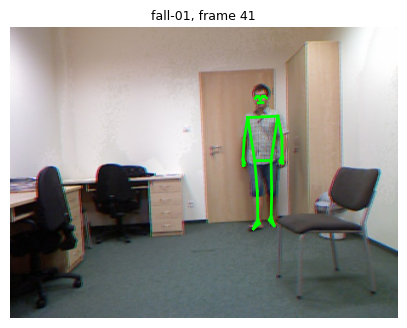

In [2]:
number, path = frames_of("fall-01")[40]
image = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

with make_detector("image") as detector:
    result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=image))

joints = np.array([[p.x, p.y] for p in result.pose_landmarks[0]])
print("joints found:", len(joints))
print("nose (x, y):", joints[0].round(3), "| left hip (x, y):", joints[23].round(3))
fig, ax = plt.subplots(figsize=(5, 4)); draw(ax, image, joints, f"fall-01, frame {number}"); plt.show()

💡 **Interpretation:** the nose (y = 0.25) has a **smaller y** than the hip (y = 0.46) because image y grows downwards: higher on screen = smaller y. Remember this for the rules in notebook 04.

## Step 2 — Process a whole video

MediaPipe has two modes:
- **IMAGE**: every frame is analysed alone;
- **VIDEO**: the model *follows* the person from one frame to the next, using the previous position as a starting point. This is steadier and finds people more often, especially when they lie on the floor. VIDEO mode needs the time of each frame (frame number / 30 fps).

We use VIDEO mode. When no person is found, the frame gets empty values (NaN), not zeros, so it cannot be mistaken for a real position.

In [3]:
def skeletons_of(video):
    rows = []
    with make_detector("video") as detector:
        for number, path in frames_of(video):
            image = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
            result = detector.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=image),
                                               int(number * 1000 / 30))
            row = {"video": video, "frame": number, "detected": bool(result.pose_landmarks)}
            for j, name in enumerate(JOINTS):
                p = result.pose_landmarks[0][j] if result.pose_landmarks else None
                row[f"{name}_x"] = p.x if p else np.nan
                row[f"{name}_y"] = p.y if p else np.nan
                row[f"{name}_vis"] = p.visibility if p else np.nan
            rows.append(row)
    return pd.DataFrame(rows)

one = skeletons_of("fall-01")
print(one.shape, "| person found in", f"{one.detected.mean():.0%}", "of the frames")
one[["video", "frame", "detected", "nose_x", "nose_y", "nose_vis"]].head()

(160, 102) | person found in 89% of the frames


,video,frame,detected,nose_x,nose_y,nose_vis
0,fall-01,1,True,0.653310,0.259847,0.999915
1,fall-01,2,True,0.651755,0.259849,0.999916
2,fall-01,3,True,0.651349,0.260457,0.999919
3,fall-01,4,True,0.649673,0.260679,0.999926
4,fall-01,5,True,0.647811,0.260651,0.999932


💡 **Interpretation:** the person is found in 89% of `fall-01`'s frames; all 17 missed frames are **lying on the floor** (frames 129-146): pose models are trained mostly on upright people.

## Step 3 — All 70 videos

This loop takes about **20 minutes** (11,936 frames). The result is saved, so if `skeletons.csv` already exists we just load it.

In [4]:
if OUT.exists():
    skel = pd.read_csv(OUT)
else:
    videos = sorted(p.name for p in (ROOT / "rgb").iterdir() if p.is_dir())
    parts = []
    for i, video in enumerate(videos, 1):
        parts.append(skeletons_of(video))
        print(f"[{i}/{len(videos)}] {video}: person found in {parts[-1].detected.mean():.0%} of frames", flush=True)
    skel = pd.concat(parts, ignore_index=True)
    OUT.parent.mkdir(parents=True, exist_ok=True)
    skel.to_csv(OUT, index=False)
print(skel.shape)

(11936, 102)


💡 **Interpretation:** 11,936 frames × 102 columns (video, frame, detected + 33 joints × 3 values). Most videos are found well; the hardest are `adl-19` (45%), `adl-22` (50%) and `fall-19` (52%).

## Step 4 — How often is the person found?

We join the frame labels (from the dataset) to see where MediaPipe struggles: standing, falling or lying.

In [5]:
labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]
skel_l = skel.merge(labels, on=["video", "frame"], how="left")
skel_l["kind"] = skel_l.video.str.split("-").str[0]
skel_l["phase"] = skel_l.frame_label.map({-1: "not lying", 0: "falling", 1: "lying"}).fillna("no label")

rate = skel_l.pivot_table(index="kind", columns="phase", values="detected", aggfunc="mean").round(2)
print(f"person found in {skel.detected.mean():.0%} of all frames")
rate

person found in 82% of all frames


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_16808\334275092.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  skel_l["kind"] = skel_l.video.str.split("-").str[0]
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_16808\334275092.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  skel_l["phase"] = skel_l.frame_label.map({-1: "not lying", 0: "falling", 1: "lying"}).fillna("no label")


phase,falling,lying,no label,not lying
kind,,,,
adl,1.00,0.57,0.12,0.85
fall,0.98,0.78,NaN,1.00


💡 **Interpretation:** upright people are found almost always (85-100%), **lying people much less** (78% in falls, 57% in ADLs). Unlabeled frames (12%) are mostly at the start of ADLs, often an empty room.

## Step 5 — Look at the results (and the mistakes)

Numbers are not enough: let us draw the skeletons on frames from each phase of one fall, and on a daily activity where the person lies down.

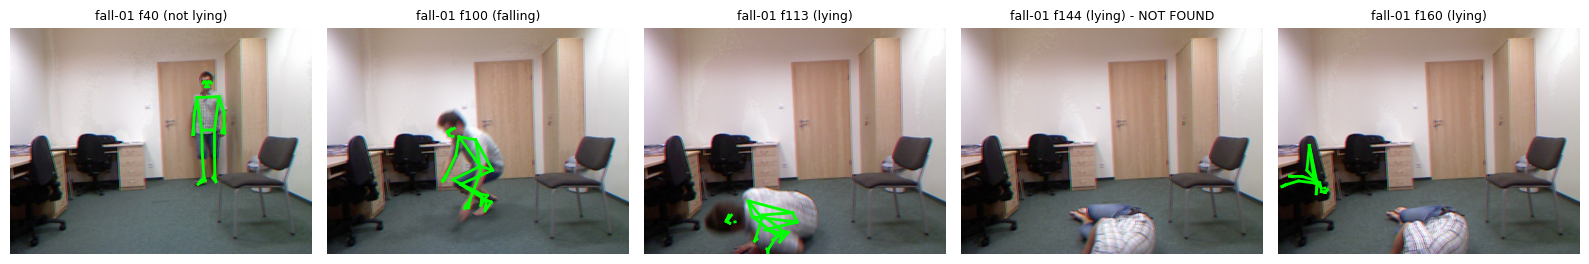

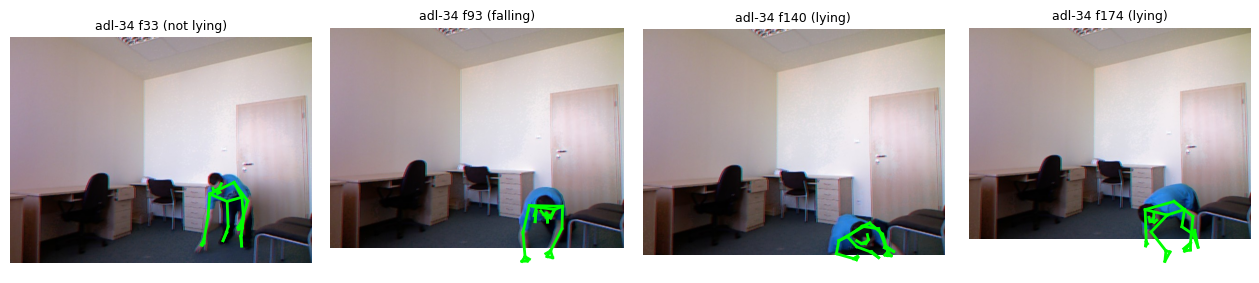

In [6]:
def show(video, frame_numbers):
    files = dict(frames_of(video))
    rows = skel[skel.video == video].set_index("frame")
    fig, axes = plt.subplots(1, len(frame_numbers), figsize=(3.2 * len(frame_numbers), 2.8))
    for ax, n in zip(axes, frame_numbers):
        image = cv2.cvtColor(cv2.imread(str(files[n])), cv2.COLOR_BGR2RGB)
        r = rows.loc[n]
        joints = np.array([[r[f"{j}_x"], r[f"{j}_y"]] for j in JOINTS]) if r.detected else None
        phase = skel_l[(skel_l.video == video) & (skel_l.frame == n)].phase.iloc[0]
        draw(ax, image, joints, f"{video} f{n} ({phase}){'' if r.detected else ' - NOT FOUND'}")
    plt.tight_layout(); plt.show()

show("fall-01", [40, 100, 113, 144, 160])
show("adl-34", [33, 93, 140, 174])

💡 **Interpretation:** standing and falling skeletons are correct, but lying is hard: in `fall-01` frame 144 nobody is found and in frame 160 the skeleton is **on the chair**, not on the person.

## What we learned

1. MediaPipe finds the person in **82%** of all frames: almost always when upright, much less when lying (78% in falls, 57% in ADLs), because pose models are mostly trained on upright people.
2. Some skeletons are **wrong**, not just missing (e.g. placed on a chair next to the person lying on the floor).
3. Consequence for the next notebooks: missing frames are normal, so the methods must not rely on a single frame; they look at how the skeleton changes **over time**.

**Next notebook (04):** a state machine that reads these skeletons over time and decides Standing → Falling → Lying → Fall Detected.